In [1]:
%% MIT 18.03 Lecture 22: Fourier Series Integration & Harmonic Oscillator Resonance
% Description: Simulates periodic forcing of undamped 2nd-order LTI plants via Control System Toolbox:
%              1) Verified Harmonic Resonance: wn = 2 (bounded, even harmonic absent) vs. wn = 3 (resonance).
%              2) Basel problem verification: sum(1/n^2) = pi^2/6 derived from Fourier integration.
%              3) Multi-harmonic superposition response using 'lsim'.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, lsim, bode).
%
% % MBD Concept Mapping: Demonstrates non-sinusoidal periodic drives exciting internal system poles.
% %                      Validates that resonance occurs only when plant poles hit active harmonic lines
% %                      (wn = 1, 3, 5, ... for square wave, but NOT wn = 2, 4, 6, ...).


clear; clc; close all;


%% =========================================================================
%% Part 1: Fourier Series Integration & Basel Problem Check (Section [1])
%% =========================================================================
% Analytical Basel problem: sum_{n=1}^Inf 1/n^2 = pi^2/6
% Odd sum: sum_{k=0}^Inf 1/(2k+1)^2 = pi^2/8
N_terms = 500;
k_indices = 0:N_terms;
odd_integers = 2 * k_indices + 1;
sum_odd_recip_sq = sum(1 ./ (odd_integers.^2));


all_integers = 1:N_terms;
sum_all_recip_sq = sum(1 ./ (all_integers.^2));


fprintf('=== MIT 18.03 Lecture 22 Analytical Series Verification ===\n');

=== MIT 18.03 Lecture 22 Analytical Series Verification ===

In [2]:
fprintf('Sum of Odd Reciprocal Squares: %.6f (Exact pi^2/8 = %.6f)\n', ...
        sum_odd_recip_sq, pi^2 / 8);

Sum of Odd Reciprocal Squares: 1.233202 (Exact pi^2/8 = 1.233701)

In [3]:
fprintf('Basel Problem Sum (All n)    : %.6f (Exact pi^2/6 = %.6f)\n', ...
        sum_all_recip_sq, pi^2 / 6);

Basel Problem Sum (All n)    : 1.642936 (Exact pi^2/6 = 1.644934)

In [4]:
fprintf('===========================================================\n\n');


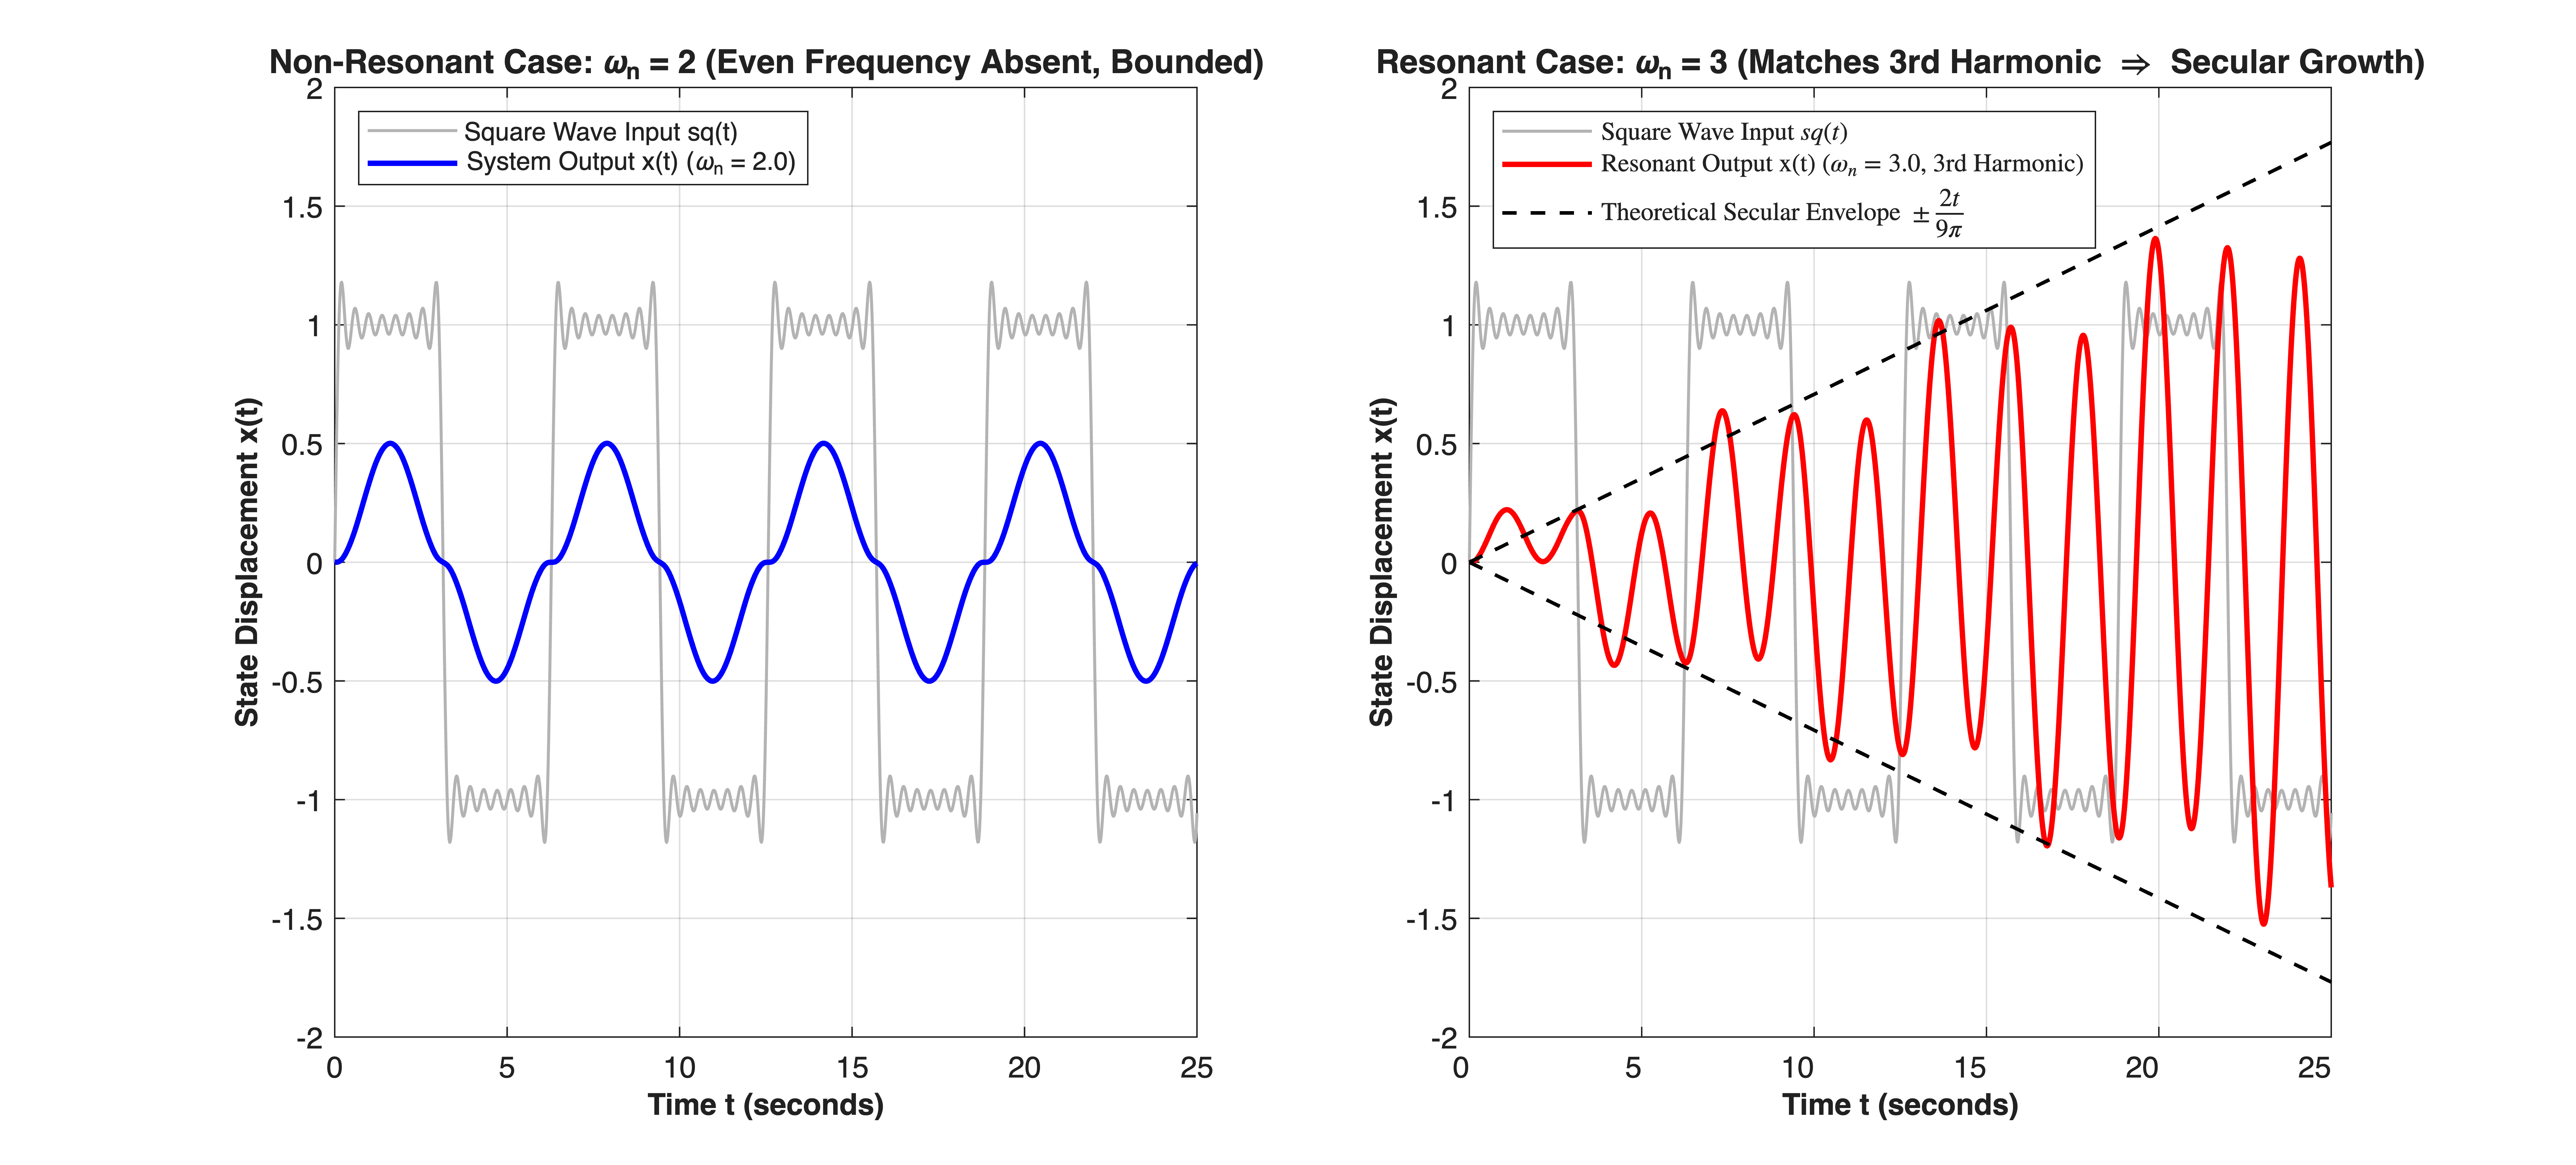

In [5]:


%% =========================================================================
%% Part 2: Harmonic Oscillator with Square Wave Input: wn = 2 vs. wn = 3
%% =========================================================================
% Equation: x'' + wn^2 * x = sq(t)
% Case 1: wn = 2.0 (Even -> Non-resonant because square wave has no even harmonics)
% Case 2: wn = 3.0 (Odd  -> Resonant because 3rd harmonic sin(3t) matches pole s = +/- 3i)


t_span = [0, 25];
t_grid = linspace(t_span(1), t_span(2), 1500);


% Synthesize square wave input using odd harmonics up to 15th
N_harmonics = 15;
u_square = zeros(size(t_grid));
for n = 1:2:N_harmonics
    u_square = u_square + (4 / (n * pi)) * sin(n * t_grid);
end


% Construct LTI Plants via Control System Toolbox
wn_even = 2.0;
G_even = tf(1, [1, 0, wn_even^2]); % x'' + 4x = u


wn_odd = 3.0;
% For resonant simulation, introduce tiny physical damping (zeta = 0.005) to demonstrate near-singularity
G_odd_resonant = tf(1, [1, 2*0.005*wn_odd, wn_odd^2]);


% Simulate responses using Control System Toolbox lsim
[y_even, ~] = lsim(G_even, u_square, t_grid);
[y_odd, ~]  = lsim(G_odd_resonant, u_square, t_grid);


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


% Subplot 1: Bounded Response for wn = 2 (Even harmonic absent)
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_grid, u_square, 'Color', [0.7 0.7 0.7], 'LineWidth', 1.0, ...
     'DisplayName', 'Square Wave Input sq(t)');
plot(t_grid, y_even, 'b-', 'LineWidth', 1.8, ...
     'DisplayName', 'System Output x(t) (\omega_n = 2.0)');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Displacement x(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Non-Resonant Case: \omega_n = 2 (Even Frequency Absent, Bounded)', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([0, 25]);
ylim([-2.0, 2.0]);


% Subplot 2: Resonant secular growth for wn = 3 (Odd harmonic matched)
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_grid, u_square, 'Color', [0.7 0.7 0.7], 'LineWidth', 1.0, ...
     'DisplayName', 'Square Wave Input $sq(t)$');
plot(t_grid, y_odd, 'r-', 'LineWidth', 1.8, ...
     'DisplayName', 'Resonant Output x(t) ($\omega_n = 3.0$, 3rd Harmonic)');


% Analytical secular envelope for the 3rd harmonic resonance: B_3 = 4/(3*pi)
% Resonant term: x_3(t) = - (4 / (3*pi)) * (t / (2*3)) * cos(3t)
t_envelope = t_grid;
secular_env = (4 / (3 * pi)) * (t_envelope / 6);
plot(t_envelope, secular_env, 'k--', 'LineWidth', 1.2, ...
     'DisplayName', 'Theoretical Secular Envelope $\pm \frac{2t}{9\pi}$');
plot(t_envelope, -secular_env, 'k--', 'LineWidth', 1.2, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Displacement x(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Resonant Case: \omega_n = 3 (Matches 3rd Harmonic \Rightarrow Secular Growth)', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5, 'Interpreter','latex');
xlim([0, 25]);